# CRC B_2 · colorectal cancer

Saved programme maps and distance profiles. Archived section programmes; distance is retained as saved. CRC B_2/C_2 are regions, not a verified patient count. Glioma574 and SMINT P1 are kept separate from GBM, and their independence as patients is unverified. Current composition-adjusted results are in the manuscript source tables.

In [1]:
from pathlib import Path
import sys
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/sections.json").exists())
sys.path.insert(0, str(root / "notebooks"))
from section_viewer import load_section, plot_section

SECTION = "CRC_B_2"
config, data, members, profiles = load_section(SECTION)
print(config["title"])
print(f"{config['n_positions']:,} positions; {config['n_members']:,} listed ions")

CRC B_2 · colorectal cancer
2,013 positions; 27 listed ions


## Programme maps and profiles

Profiles are means in 32 equal-width distance bins. Empty bins remain missing. Maps use the saved scores, with a common display range of −2.5 to 2.5. No model is fitted in these cells.

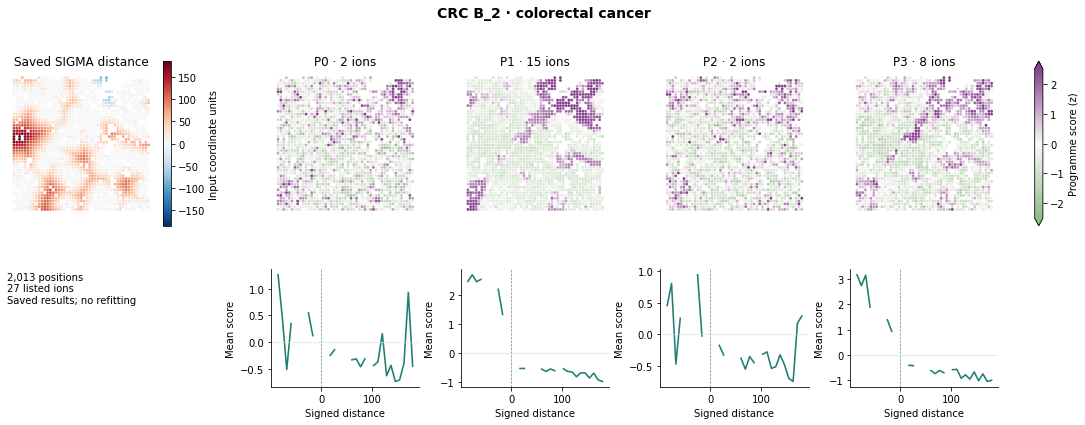

In [2]:
import matplotlib.pyplot as plt
fig = plot_section(config, data, members, profiles)
plt.show()

## Molecular members

Programme numbers are local to this section and analysis. Matching numbers in different notebooks do not imply matching molecular members.

In [3]:
display(members.groupby("programme").size().rename("n_ions").to_frame())
display(members.head(12))

,n_ions
programme,
P0,2
P1,15
P2,2
P3,8


,j,mz,lambda,r2_logI,slope,intercept,n_valid,boundary_enrichment_ratio,detect_rate,interface_log2FC_near_vs_far,interface_score,feature_id,sigma_sm_index,cluster,ion_label,programme
0,11,NaN,19237.645739,0.170891,-0.000052,0.010759,2013,1.666137,0.999006,0.736507,0.836478,11,11,3,Feature 0011,P3
1,94,NaN,22521.282058,0.155184,-0.000044,0.009681,2013,1.658818,0.999503,0.730156,0.817610,94,94,1,Feature 0094,P1
2,106,NaN,19628.431553,0.123819,-0.000051,0.007274,2013,2.304691,1.000000,1.204573,0.911950,106,106,1,Feature 0106,P1
3,109,NaN,24290.171688,0.112118,-0.000041,0.008957,2013,1.611691,0.997019,0.688575,0.742138,109,109,3,Feature 0109,P3
4,108,NaN,27825.947143,0.110318,-0.000036,0.006890,2013,1.908777,0.997516,0.932648,0.836478,108,108,1,Feature 0108,P1
5,110,NaN,26525.072079,0.098246,-0.000038,0.009599,2013,1.523908,0.998013,0.607775,0.666667,110,110,3,Feature 0110,P3
6,96,NaN,28912.936175,0.094172,-0.000035,0.006548,2013,1.958306,0.999503,0.969606,0.836478,96,96,1,Feature 0096,P1
7,105,NaN,20009.828083,0.086205,-0.000050,0.011664,2013,1.335364,1.000000,0.417233,0.603774,105,105,3,Feature 0105,P3
8,9,NaN,38610.369060,0.072377,-0.000026,0.004238,2013,2.137187,0.954794,1.095713,0.849057,9,9,1,Feature 0009,P1
9,103,NaN,39199.753149,0.059558,-0.000026,0.006965,2013,1.438306,0.992548,0.524371,0.616352,103,103,3,Feature 0103,P3


## Recalculate from a saved model

Optional: provide the full fitted AnnData file and set `RUN_ANALYSIS=True`. This keeps the fitted probability field, updates its continuous distance, and reruns ion selection and programme analysis with version 0.3.2. New programme numbers may differ. The full AnnData file is not included in the preview data; see `docs/input_format.md`. This step requires Python 3.11 and sigma-omics 0.3.2.

In [4]:
RUN_ANALYSIS = False
INPUT_H5AD = None  # Path to your full fitted AnnData object.

if RUN_ANALYSIS:
    if INPUT_H5AD is None:
        raise ValueError("Set INPUT_H5AD to the fitted AnnData file first.")
    import scanpy as sc
    from sigma_spatial import update_interface_coordinate, run_downstream_analysis

    fitted = sc.read_h5ad(INPUT_H5AD)
    updated = update_interface_coordinate(fitted, copy=True)
    report = run_downstream_analysis(
        updated, output_dir=root / "results" / SECTION / "continuous",
        prefix=SECTION, matrix_source="X",
        selection_mode="standardized", report_level="standard", random_state=0,
    )
    print(report.output_dir)
else:
    print("Viewing saved results. Set INPUT_H5AD and RUN_ANALYSIS to recalculate.")

Viewing saved results. Set INPUT_H5AD and RUN_ANALYSIS to recalculate.
